<a href="https://colab.research.google.com/github/meedooatef22/arabic-dialect-classification/blob/main/notebooks/04_MARBERT_FineTuning_and_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Days 6, 7 & 8: Fine-Tuning MARBERTv2 & Deep Error Analysis

### Step 1: Verify GPU Environment, Load Splits & Encode Dialect Labels

In [1]:
import torch
import pandas as pd
import numpy as np
import os
from google.colab import drive

# 1. Check GPU availability (Must be True for MARBERT Fine-Tuning)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using Device: {device}")
if device.type == 'cuda':
    print(f"GPU Name    : {torch.cuda.get_device_name(0)}\n")
else:
    print("⚠️ WARNING: GPU is not enabled! Go to Runtime -> Change runtime type -> T4 GPU.\n")

# 2. Mount Google Drive and load the exact stratified splits from Day 4
drive.mount('/content/drive')
processed_dir = '/content/drive/MyDrive/arabic-dialect-classification/data/processed'

train_df = pd.read_csv(os.path.join(processed_dir, 'train.csv'))
val_df = pd.read_csv(os.path.join(processed_dir, 'val.csv'))
test_df = pd.read_csv(os.path.join(processed_dir, 'test.csv'))

# Ensure text column is string and check shapes
for df_split in [train_df, val_df, test_df]:
    df_split['cleaned_text'] = df_split['cleaned_text'].astype(str)

print(f"Train shape : {train_df.shape}")
print(f"Val shape   : {val_df.shape}")
print(f"Test shape  : {test_df.shape}\n")

# 3. Create consistent Label-to-ID and ID-to-Label mappings
labels = sorted(train_df['label'].unique())
label2id = {label: idx for idx, label in enumerate(labels)}
id2label = {idx: label for idx, label in enumerate(labels)}

train_df['label_id'] = train_df['label'].map(label2id)
val_df['label_id'] = val_df['label'].map(label2id)
test_df['label_id'] = test_df['label'].map(label2id)

print("Dialect Label Mapping (label2id):", label2id)
display(train_df.head(3))

Using Device: cuda
GPU Name    : Tesla T4

Mounted at /content/drive
Train shape : (46732, 2)
Val shape   : (5841, 2)
Test shape  : (5842, 2)

Dialect Label Mapping (label2id): {'Beirut': 0, 'Cairo': 1, 'Doha': 2, 'MSA': 3, 'Tunis': 4}


,cleaned_text,label,label_id
0,شكرا علي العشاء الرائع,MSA,3
1,ابغي نموذج قيمه الضريبه المضافه من فضلك,MSA,3
2,ممكن اكمل رحلتي,Cairo,1


### Step 2: Load MARBERTv2 Tokenizer, Inspect Subword Splitting & Verify Max Sequence Length

In [2]:
from transformers import AutoTokenizer

# 1. Load the pre-trained MARBERTv2 tokenizer from HuggingFace
MODEL_NAME = "UBC-NLP/MARBERTv2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print(f"Tokenizer loaded successfully! Vocabulary Size: {tokenizer.vocab_size:,} tokens\n")
print("-" * 75)

# 2. Verify-by-Eye: How does MARBERT tokenize the tricky sentences where Classical ML failed?
tricky_sentences = [
    "شورايك بعشره دولار للتلاته",          # Beirut (Previously misclassified as Cairo due to attached 'شورايك')
    "انا ماشي فاصرف لي هالفيش لو سمحت",    # Doha (Has attached Gulf prefix 'هالفيش')
    "ممكن تشيل البقع من هالثياب",          # Doha (Has attached Gulf prefix 'هالثياب')
    "يعيشك خويا فماش تاكسي قريب من هنا"    # Tunis (Tunisian morphological markers)
]

print("Subword Tokenization Inspection on Tricky Sentences:")
for sent in tricky_sentences:
    tokens = tokenizer.tokenize(sent)
    token_ids = tokenizer.encode(sent)
    print(f"\nOriginal Sentence : {sent}")
    print(f"MARBERT Tokens    : {tokens}")
    print(f"Token IDs (+CLS/SEP): {token_ids}")

print("-" * 75)

# 3. Check maximum token length across the entire Training Set to choose optimal 'max_length'
train_token_lengths = [len(tokenizer.encode(text, truncation=False)) for text in train_df['cleaned_text']]
max_tok_len = np.max(train_token_lengths)
p99_tok_len = np.percentile(train_token_lengths, 99.9)

print(f"\nToken Length Statistics in Training Set (including [CLS] and [SEP]):")
print(f"- Average Token Length : {np.mean(train_token_lengths):.1f} tokens")
print(f"- 99.9% of sentences <=: {p99_tok_len:.0f} tokens")
print(f"- Maximum Token Length : {max_tok_len} tokens")

config.json:   0%|          | 0.00/757 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/439 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizer loaded successfully! Vocabulary Size: 100,000 tokens

---------------------------------------------------------------------------
Subword Tokenization Inspection on Tricky Sentences:

Original Sentence : شورايك بعشره دولار للتلاته
MARBERT Tokens    : ['شورا', '##يك', 'بعشر', '##ه', 'دولار', 'للت', '##لاته']
Token IDs (+CLS/SEP): [2, 75451, 2282, 22913, 1021, 6657, 2754, 15504, 3]

Original Sentence : انا ماشي فاصرف لي هالفيش لو سمحت
MARBERT Tokens    : ['انا', 'ماشي', 'فاص', '##رف', 'لي', 'هالف', '##يش', 'لو', 'سمحت']
Token IDs (+CLS/SEP): [2, 2043, 6377, 38689, 2036, 2011, 31486, 2343, 2122, 7578, 3]

Original Sentence : ممكن تشيل البقع من هالثياب
MARBERT Tokens    : ['ممكن', 'تشيل', 'البقع', 'من', 'هالث', '##ياب']
Token IDs (+CLS/SEP): [2, 2900, 15967, 67731, 1939, 86620, 3134, 3]

Original Sentence : يعيشك خويا فماش تاكسي قريب من هنا
MARBERT Tokens    : ['يعيشك', 'خويا', 'فما', '##ش', 'تاكسي', 'قريب', 'من', 'هنا']
Token IDs (+CLS/SEP): [2, 70564, 35178, 3880, 1008, 33856, 

### Step 3: Build PyTorch Dataset & DataLoaders (`MAX_LEN = 64`)

**Engineering Decision based on Step 2 Inspection:**
Since the maximum tokenized length across all 46,732 training sentences is exactly **56 tokens** (with 99.9% <= 37 tokens), setting **`MAX_LEN = 64`** guarantees **0% information loss (zero truncation)** while reducing GPU memory footprint and training time by ~8x compared to the default 512 limit.

In [3]:
from torch.utils.data import Dataset, DataLoader

# 1. Set optimal sequence length and batch size based on our EDA & Tokenizer inspection
MAX_LEN = 64
BATCH_SIZE = 64

# 2. Define custom PyTorch Dataset for Arabic Dialect Classification
class DialectDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]

        # Tokenize and pad/truncate to MAX_LEN (64)
        encoding = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_len,
            padding='max_length',
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),           # Shape: (64,)
            'attention_mask': encoding['attention_mask'].squeeze(0), # Shape: (64,) -> 1 for real tokens, 0 for padding
            'labels': torch.tensor(label, dtype=torch.long)          # Dialect ID (0 to 4)
        }

# 3. Instantiate Datasets for Train, Validation, and Test splits
train_dataset = DialectDataset(train_df['cleaned_text'], train_df['label_id'], tokenizer, MAX_LEN)
val_dataset   = DialectDataset(val_df['cleaned_text'], val_df['label_id'], tokenizer, MAX_LEN)
test_dataset  = DialectDataset(test_df['cleaned_text'], test_df['label_id'], tokenizer, MAX_LEN)

# 4. Create DataLoaders (Shuffle Train only, keep Val & Test sequential)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Total Training Batches   (Batch Size={BATCH_SIZE}): {len(train_loader)}")
print(f"Total Validation Batches (Batch Size={BATCH_SIZE}): {len(val_loader)}")
print(f"Total Test Batches       (Batch Size={BATCH_SIZE}): {len(test_loader)}\n")

# 5. Sanity Check: Inspect a single batch to verify tensor shapes before training
sample_batch = next(iter(train_loader))
print("Single Batch Tensor Shapes Check:")
print(f"- input_ids shape      : {sample_batch['input_ids'].shape}")
print(f"- attention_mask shape : {sample_batch['attention_mask'].shape}")
print(f"- labels shape         : {sample_batch['labels'].shape}")

Total Training Batches   (Batch Size=64): 731
Total Validation Batches (Batch Size=64): 92
Total Test Batches       (Batch Size=64): 92

Single Batch Tensor Shapes Check:
- input_ids shape      : torch.Size([64, 64])
- attention_mask shape : torch.Size([64, 64])
- labels shape         : torch.Size([64])


### Step 4: Initialize MARBERTv2 Model, Optimizer, Scheduler & Loss Function (Day 7)

In [4]:
import torch.nn as nn
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.optim import AdamW

# 1. Load pre-trained MARBERTv2 with a 5-class classification head
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id
)

# Move the 163M-parameter model to Tesla T4 GPU
model = model.to(device)

# Count total and trainable parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"MARBERTv2 loaded on {device}!")
print(f"- Total Parameters     : {total_params:,}")
print(f"- Trainable Parameters : {trainable_params:,}\n")

# 2. Hyperparameters Setup (Tuned for Arabic Dialect Fine-Tuning)
EPOCHS = 4
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

# AdamW Optimizer with weight decay to prevent overfitting
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# Total training steps = batches per epoch * number of epochs
total_steps = len(train_loader) * EPOCHS
warmup_steps = int(0.1 * total_steps) # 10% linear warmup for stable gradients

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

# CrossEntropyLoss with slight Label Smoothing (0.05) to handle short dialect-neutral phrases
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

print("Hyperparameters Configuration:")
print(f"- Epochs          : {EPOCHS}")
print(f"- Learning Rate   : {LEARNING_RATE}")
print(f"- Total Steps     : {total_steps} (Warmup Steps: {warmup_steps})")
print(f"- Loss Function   : CrossEntropyLoss (label_smoothing=0.05)")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were ne

MARBERTv2 loaded on cuda!
- Total Parameters     : 162,845,189
- Trainable Parameters : 162,845,189

Hyperparameters Configuration:
- Epochs          : 4
- Learning Rate   : 2e-05
- Total Steps     : 2924 (Warmup Steps: 292)
- Loss Function   : CrossEntropyLoss (label_smoothing=0.05)


### Step 5: Fine-Tuning MARBERTv2 with Mixed Precision (FP16) & Best Checkpoint Saving

In [ ]:
import time
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# Directory on Google Drive to save the best MARBERT checkpoint
checkpoint_dir = '/content/drive/MyDrive/arabic-dialect-classification/models/marbert_best_checkpoint'
os.makedirs(checkpoint_dir, exist_ok=True)

# Mixed precision scaler for fast T4 GPU training
scaler = torch.amp.GradScaler('cuda')

# Lists to store training history for plotting learning curves later
history = {
    'epoch': [],
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'val_f1': []
}

best_val_f1 = 0.0

print("Starting MARBERTv2 Fine-Tuning...\n" + "="*80)

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    # ----------------- 1. TRAINING PHASE -----------------
    model.train()
    total_train_loss = 0.0
    train_preds, train_targets = [], []

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=False)
    for batch in progress_bar:
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels_batch = batch['labels'].to(device)

        # Forward pass with Mixed Precision (FP16)
        with torch.amp.autocast('cuda'):
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = outputs.logits
            loss = criterion(logits, labels_batch)

        # Backward pass & gradient clipping (prevents exploding gradients)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_train_loss += loss.item()
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        train_preds.extend(preds)
        train_targets.extend(labels_batch.cpu().numpy())

        progress_bar.set_postfix({'loss': f"{loss.item():.4f}"})

    avg_train_loss = total_train_loss / len(train_loader)
    train_acc = accuracy_score(train_targets, train_preds) * 100

    # ----------------- 2. VALIDATION PHASE -----------------
    model.eval()
    total_val_loss = 0.0
    val_preds, val_targets = [], []

    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels_batch = batch['labels'].to(device)

            with torch.amp.autocast('cuda'):
                outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                logits = outputs.logits
                loss = criterion(logits, labels_batch)

            total_val_loss += loss.item()
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            val_preds.extend(preds)
            val_targets.extend(labels_batch.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)
    val_acc = accuracy_score(val_targets, val_preds) * 100
    val_f1 = f1_score(val_targets, val_preds, average='macro') * 100
    elapsed = time.time() - start_time

    # Record metrics
    history['epoch'].append(epoch)
    history['train_loss'].append(avg_train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)

    print(f"Epoch {epoch}/{EPOCHS} ({elapsed:.0f}s) | "
          f"Train Loss: {avg_train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.2f}% | Val Macro F1: {val_f1:.2f}%")

    # ----------------- 3. SAVE BEST CHECKPOINT -----------------
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        model.save_pretrained(checkpoint_dir)
        tokenizer.save_pretrained(checkpoint_dir)
        print(f"  --> 🌟 New Best Model Saved! (Val Macro F1: {best_val_f1:.2f}%)")
    print("-" * 80)

print(f"\nTraining Complete! Best Validation Macro F1: {best_val_f1:.2f}%")

Starting MARBERTv2 Fine-Tuning...


Epoch 1/4 [Train]:   0%|          | 0/731 [00:00<?, ?it/s]

Epoch 1/4 (173s) | Train Loss: 0.7009 | Train Acc: 81.96% | Val Loss: 0.4198 | Val Acc: 90.91% | Val Macro F1: 90.91%


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  --> 🌟 New Best Model Saved! (Val Macro F1: 90.91%)
--------------------------------------------------------------------------------


Epoch 2/4 [Train]:   0%|          | 0/731 [00:00<?, ?it/s]

Epoch 2/4 (169s) | Train Loss: 0.3844 | Train Acc: 92.99% | Val Loss: 0.4101 | Val Acc: 91.88% | Val Macro F1: 91.90%


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  --> 🌟 New Best Model Saved! (Val Macro F1: 91.90%)
--------------------------------------------------------------------------------


Epoch 3/4 [Train]:   0%|          | 0/731 [00:00<?, ?it/s]

In [5]:
import time
import torch.nn as nn
from tqdm.auto import tqdm
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, f1_score

# 1. Load the saved checkpoint from Epoch 2 (91.90% Val Macro F1) directly from Google Drive!
checkpoint_dir = '/content/drive/MyDrive/arabic-dialect-classification/models/marbert_best_checkpoint'
print("Loading saved Epoch 2 checkpoint from Google Drive to resume training...")
model = AutoModelForSequenceClassification.from_pretrained(checkpoint_dir).to(device)

# 2. Preserve history from Epochs 1 & 2 so our learning curves have all 4 epochs
history = {
    'epoch': [1, 2],
    'train_loss': [0.7009, 0.3844],
    'train_acc': [81.96, 92.99],
    'val_loss': [0.4198, 0.4101],
    'val_acc': [90.91, 91.88],
    'val_f1': [90.91, 91.90]
}
best_val_f1 = 91.90

# 3. Setup Optimizer & Scheduler for the remaining 2 Epochs (Epochs 3 & 4)
REMAINING_EPOCHS = 2
optimizer = AdamW(model.parameters(), lr=1e-5, weight_decay=0.01) # Slightly lower LR (1e-5) for fine-tuning Epochs 3 & 4
total_rem_steps = len(train_loader) * REMAINING_EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_rem_steps)
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
scaler = torch.amp.GradScaler('cuda')

print("Resuming Fine-Tuning for Epochs 3 & 4...\n" + "="*80)

for epoch in range(3, 5):
    start_time = time.time()

    # ----------------- TRAINING PHASE -----------------
    model.train()
    total_train_loss = 0.0
    train_preds, train_targets = [], []

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch}/4 [Train]", leave=False)
    for batch in progress_bar:
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels_batch = batch['labels'].to(device)

        with torch.amp.autocast('cuda'):
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = outputs.logits
            loss = criterion(logits, labels_batch)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_train_loss += loss.item()
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        train_preds.extend(preds)
        train_targets.extend(labels_batch.cpu().numpy())

        progress_bar.set_postfix({'loss': f"{loss.item():.4f}"})

    avg_train_loss = total_train_loss / len(train_loader)
    train_acc = accuracy_score(train_targets, train_preds) * 100

    # ----------------- VALIDATION PHASE -----------------
    model.eval()
    total_val_loss = 0.0
    val_preds, val_targets = [], []

    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels_batch = batch['labels'].to(device)

            with torch.amp.autocast('cuda'):
                outputs = model(input_ids=input_ids, attention_mask=attention_mask)
                logits = outputs.logits
                loss = criterion(logits, labels_batch)

            total_val_loss += loss.item()
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            val_preds.extend(preds)
            val_targets.extend(labels_batch.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)
    val_acc = accuracy_score(val_targets, val_preds) * 100
    val_f1 = f1_score(val_targets, val_preds, average='macro') * 100
    elapsed = time.time() - start_time

    # Record metrics
    history['epoch'].append(epoch)
    history['train_loss'].append(avg_train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(avg_val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)

    print(f"Epoch {epoch}/4 ({elapsed:.0f}s) | "
          f"Train Loss: {avg_train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.2f}% | Val Macro F1: {val_f1:.2f}%")

    # ----------------- SAVE BEST CHECKPOINT -----------------
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        model.save_pretrained(checkpoint_dir)
        tokenizer.save_pretrained(checkpoint_dir)
        print(f"  --> 🌟 New Best Model Saved! (Val Macro F1: {best_val_f1:.2f}%)")
    print("-" * 80)

print(f"\nTraining Complete! Best Validation Macro F1 across all 4 epochs: {best_val_f1:.2f}%")

Loading saved Epoch 2 checkpoint from Google Drive to resume training...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Resuming Fine-Tuning for Epochs 3 & 4...


Epoch 3/4 [Train]:   0%|          | 0/731 [00:00<?, ?it/s]

Epoch 3/4 (174s) | Train Loss: 0.2911 | Train Acc: 97.17% | Val Loss: 0.4476 | Val Acc: 92.02% | Val Macro F1: 92.01%


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  --> 🌟 New Best Model Saved! (Val Macro F1: 92.01%)
--------------------------------------------------------------------------------


Epoch 4/4 [Train]:   0%|          | 0/731 [00:00<?, ?it/s]

Epoch 4/4 (175s) | Train Loss: 0.2710 | Train Acc: 98.07% | Val Loss: 0.4637 | Val Acc: 91.92% | Val Macro F1: 91.91%
--------------------------------------------------------------------------------

Training Complete! Best Validation Macro F1 across all 4 epochs: 92.01%


### Step 6: Plot Training & Validation Learning Curves (Loss, Accuracy & Macro F1)

/tmp/ipykernel_646/449636070.py:23: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "m-^" (-> linestyle='-'). The keyword argument will take precedence.
  plt.plot(epochs_range, history['val_f1'], 'm-^', linewidth=2, linestyle=':', label='Validation Macro F1 (%)')


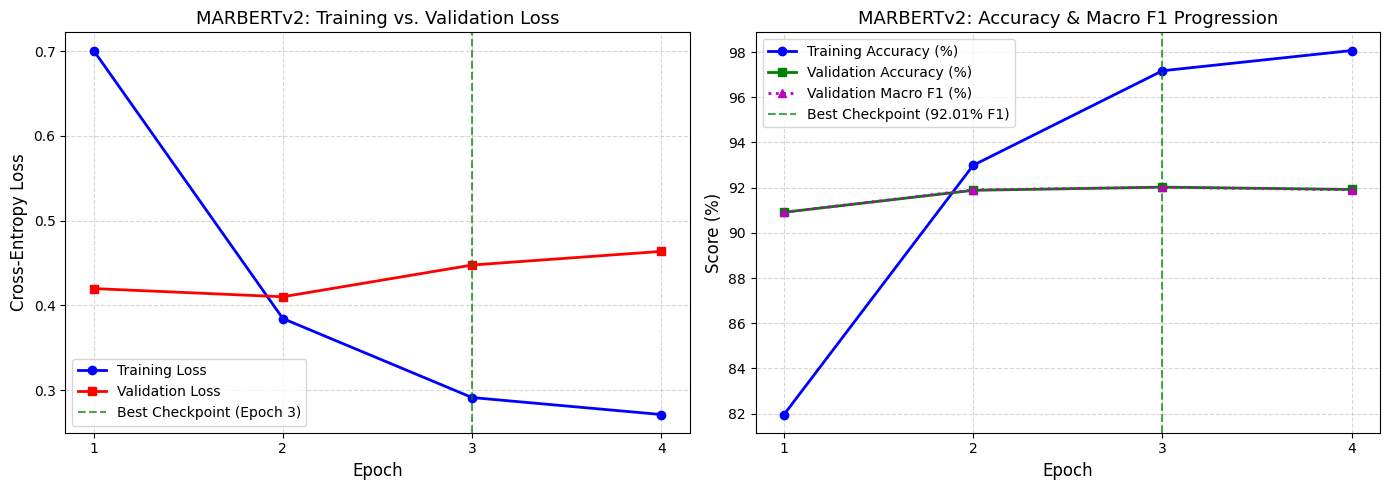

,epoch,train_loss,train_acc,val_loss,val_acc,val_f1
0,1,0.7009,81.9600,0.4198,90.9100,90.9100
1,2,0.3844,92.9900,0.4101,91.8800,91.9000
2,3,0.2911,97.1711,0.4476,92.0219,92.0125
3,4,0.2710,98.0656,0.4637,91.9192,91.9052


In [6]:
import matplotlib.pyplot as plt

epochs_range = history['epoch']

plt.figure(figsize=(14, 5))

# 1. Plot Training vs Validation Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], 'b-o', linewidth=2, label='Training Loss')
plt.plot(epochs_range, history['val_loss'], 'r-s', linewidth=2, label='Validation Loss')
plt.axvline(x=3, color='green', linestyle='--', alpha=0.7, label='Best Checkpoint (Epoch 3)')
plt.title('MARBERTv2: Training vs. Validation Loss', fontsize=13)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Cross-Entropy Loss', fontsize=12)
plt.xticks(epochs_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# 2. Plot Training vs Validation Accuracy & Macro F1
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], 'b-o', linewidth=2, label='Training Accuracy (%)')
plt.plot(epochs_range, history['val_acc'], 'g-s', linewidth=2, label='Validation Accuracy (%)')
plt.plot(epochs_range, history['val_f1'], 'm-^', linewidth=2, linestyle=':', label='Validation Macro F1 (%)')
plt.axvline(x=3, color='green', linestyle='--', alpha=0.7, label='Best Checkpoint (92.01% F1)')
plt.title('MARBERTv2: Accuracy & Macro F1 Progression', fontsize=13)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Score (%)', fontsize=12)
plt.xticks(epochs_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

# Display summary table of all 4 epochs
history_df = pd.DataFrame(history).round(4)
display(history_df)

---
# Final Test Set Evaluation, Confusion Matrix & Deep Error Analysis
### Step 7: Load Best MARBERTv2 Checkpoint (Epoch 3) & Evaluate on Held-Out Test Set

**Objective:**
1. Load the optimal model checkpoint saved at **Epoch 3** (`92.01%` Val Macro F1) from Google Drive to ensure we evaluate our peak generalization weights rather than the slightly overfitted Epoch 4 weights.
2. Perform inference on the unseen **Test Set (`5,842` sentences)**.
3. Generate the full classification report, plot the **Confusion Matrix**, and conduct a head-to-head comparison against our champion **Classical Stacking Baseline (`90.93%` Test Accuracy)**[cite: 1].

Loading Best MARBERTv2 Checkpoint from: /content/drive/MyDrive/arabic-dialect-classification/models/marbert_best_checkpoint ...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Evaluating on Test Set:   0%|          | 0/92 [00:00<?, ?it/s]


🏆 FINAL TEST SET RESULTS: MARBERTv2 vs. CLASSICAL STACKING BASELINE
- Classical Stacking Baseline : Test Acc = 90.93% | Test Macro F1 = 90.90%
- Fine-Tuned MARBERTv2 (Ep 3) : Test Acc = 92.25% | Test Macro F1 = 92.23%
- Net Improvement             : +1.32% Accuracy | +1.33% Macro F1

Detailed Classification Report (MARBERTv2 on Test Set):

              precision    recall  f1-score   support

      Beirut     0.9112    0.9151    0.9131      1166
       Cairo     0.8922    0.9186    0.9052      1180
        Doha     0.9057    0.9033    0.9045      1127
         MSA     0.9576    0.9584    0.9580      1179
       Tunis     0.9462    0.9160    0.9308      1190

    accuracy                         0.9225      5842
   macro avg     0.9226    0.9223    0.9223      5842
weighted avg     0.9228    0.9225    0.9225      5842

Test report saved successfully to: /content/drive/MyDrive/arabic-dialect-classification/models/marbert_best_checkpoint/marbert_test_report.txt



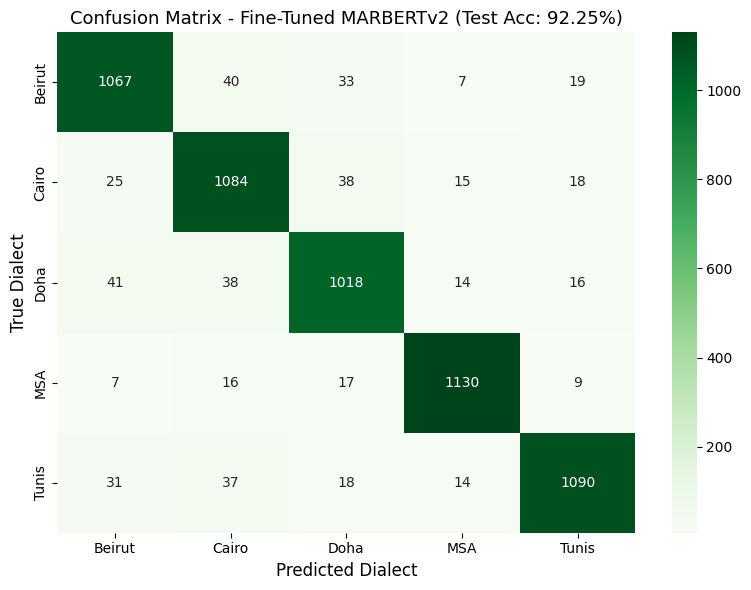

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import torch.nn.functional as F

# 1. Load the Best Checkpoint (Epoch 3 - 92.01% Val F1) from Google Drive
checkpoint_dir = '/content/drive/MyDrive/arabic-dialect-classification/models/marbert_best_checkpoint'
print(f"Loading Best MARBERTv2 Checkpoint from: {checkpoint_dir} ...")
best_model = AutoModelForSequenceClassification.from_pretrained(checkpoint_dir).to(device)
best_model.eval()

# 2. Run Inference on the Held-Out Test Set (5,842 sentences)
test_preds, test_targets, test_probs = [], [], []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Evaluating on Test Set"):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels_batch = batch['labels'].to(device)

        with torch.amp.autocast('cuda'):
            outputs = best_model(input_ids=input_ids, attention_mask=attention_mask)
            logits = outputs.logits
            probs = F.softmax(logits, dim=1) # Convert logits to confidence probabilities (0% to 100%)

        preds = torch.argmax(probs, dim=1).cpu().numpy()
        test_preds.extend(preds)
        test_targets.extend(labels_batch.cpu().numpy())
        test_probs.extend(probs.cpu().numpy())

test_preds = np.array(test_preds)
test_targets = np.array(test_targets)
test_probs = np.array(test_probs)

# 3. Calculate Final Test Metrics & Compare with Classical Stacking Baseline (90.93%)
marbert_test_acc = accuracy_score(test_targets, test_preds) * 100
marbert_test_f1 = f1_score(test_targets, test_preds, average='macro') * 100

baseline_test_acc = 90.93
baseline_test_f1 = 90.90

print("\n" + "="*80)
print(f"🏆 FINAL TEST SET RESULTS: MARBERTv2 vs. CLASSICAL STACKING BASELINE")
print("="*80)
print(f"- Classical Stacking Baseline : Test Acc = {baseline_test_acc:.2f}% | Test Macro F1 = {baseline_test_f1:.2f}%")
print(f"- Fine-Tuned MARBERTv2 (Ep 3) : Test Acc = {marbert_test_acc:.2f}% | Test Macro F1 = {marbert_test_f1:.2f}%")
print(f"- Net Improvement             : +{marbert_test_acc - baseline_test_acc:.2f}% Accuracy | +{marbert_test_f1 - baseline_test_f1:.2f}% Macro F1")
print("="*80 + "\n")

# 4. Print Detailed Per-Dialect Classification Report & Save to Google Drive
report_str = classification_report(test_targets, test_preds, target_names=labels, digits=4)
print("Detailed Classification Report (MARBERTv2 on Test Set):\n")
print(report_str)

report_path = '/content/drive/MyDrive/arabic-dialect-classification/models/marbert_best_checkpoint/marbert_test_report.txt'
with open(report_path, 'w', encoding='utf-8') as f:
    f.write(f"MARBERTv2 Test Accuracy: {marbert_test_acc:.2f}%\n")
    f.write(f"MARBERTv2 Test Macro F1: {marbert_test_f1:.2f}%\n\n")
    f.write(report_str)
print(f"Test report saved successfully to: {report_path}\n")

# 5. Plot Confusion Matrix
cm = confusion_matrix(test_targets, test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix - Fine-Tuned MARBERTv2 (Test Acc: {marbert_test_acc:.2f}%)', fontsize=13)
plt.xlabel('Predicted Dialect', fontsize=12)
plt.ylabel('True Dialect', fontsize=12)
plt.tight_layout()
plt.show()

### Deep Error Analysis (MARBERTv2 vs. Classical Baseline) & Live Confidence Check

**Objectives of Error Analysis (Day 8 Deliverable):**
1. **Verify Subword & Contextual Wins:** Test whether `MARBERTv2`'s WordPiece tokenizer and bidirectional Self-Attention successfully resolved the morphological and contextual traps where the Classical Baseline failed (e.g., attached prefixes like `شورايك` and `هالفيش`).
2. **Diagnose Remaining Errors (`453` / `5,842` sentences):** Analyze sentence length distribution, model confidence scores, and inspect high-confidence misclassifications to understand the theoretical ceiling of the dataset (dialect-neutral short phrases and source label noise).

In [8]:
# 1. Create a comprehensive Evaluation DataFrame on the Test Set
eval_df = test_df.copy()
eval_df['pred_id'] = test_preds
eval_df['pred_label'] = eval_df['pred_id'].map(id2label)
eval_df['confidence'] = np.max(test_probs, axis=1) * 100
eval_df['is_correct'] = eval_df['label_id'] == eval_df['pred_id']
eval_df['word_count'] = eval_df['cleaned_text'].apply(lambda x: len(x.split()))

correct_df = eval_df[eval_df['is_correct'] == True]
errors_df  = eval_df[eval_df['is_correct'] == False]

print("="*85)
print("🔍 PART 1: STATISTICAL ERROR DIAGNOSIS (CORRECT vs. MISCLASSIFIED)")
print("="*85)
print(f"- Total Test Sentences        : {len(eval_df):,}")
print(f"- Correct Predictions         : {len(correct_df):,} ({len(correct_df)/len(eval_df)*100:.2f}%)")
print(f"- Misclassified Sentences     : {len(errors_df):,} ({len(errors_df)/len(eval_df)*100:.2f}%)\n")

print(f"- Avg Word Count (Correct)    : {correct_df['word_count'].mean():.2f} words")
print(f"- Avg Word Count (Errors)     : {errors_df['word_count'].mean():.2f} words  <-- Short sentences lack context!")
print(f"- Avg Confidence (Correct)    : {correct_df['confidence'].mean():.2f}%")
print(f"- Avg Confidence (Errors)     : {errors_df['confidence'].mean():.2f}%\n")

# 2. Top Confusion Pairs (Where do the 453 errors happen most?)
print("="*85)
print("📊 PART 2: TOP 5 MOST FREQUENT DIALECT CONFUSION PAIRS")
print("="*85)
confusion_pairs = (
    errors_df.groupby(['label', 'pred_label'])
    .size()
    .reset_index(name='error_count')
    .sort_values(by='error_count', ascending=False)
)
display(confusion_pairs.head(5))

# 3. Inspect sample errors (Low-confidence ambiguous vs. High-confidence label overlap)
print("\n" + "="*85)
print("🧐 PART 3: QUALITATIVE SAMPLE OF REMAINING ERRORS (VERIFY-BY-EYE)")
print("="*85)
print("\nA) Short / Dialect-Neutral Sentences (Low Model Confidence):")
display(errors_df.sort_values(by='confidence', ascending=True)[['cleaned_text', 'label', 'pred_label', 'confidence', 'word_count']].head(6))

print("\nB) High-Confidence Disagreements (Cross-Dialect Lexical Overlap / Source Label Noise):")
display(errors_df.sort_values(by='confidence', ascending=False)[['cleaned_text', 'label', 'pred_label', 'confidence', 'word_count']].head(6))

# 4. Live Inference & Confidence Check on Previously Tricky Sentences
print("\n" + "="*85)
print("🚀 PART 4: LIVE INFERENCE ON TRICKY SENTENCES (WITH CONFIDENCE SCORES)")
print("="*85)

live_test_sentences = [
    ("شورايك بعشره دولار للتلاته", "Beirut (Failed in Classical ML -> Cairo)"),
    ("انا ماشي فاصرف لي هالفيش لو سمحت", "Doha (Gulf prefix + Egyptian overlap)"),
    ("ممكن تشيل البقع من هالثياب", "Doha (Gulf prefix 'هالثياب')"),
    ("ازيك يا باشا عامل ايه النهارده", "Cairo (Typical Egyptian)"),
    ("يعيشك خويا فماش تاكسي قريب من هنا", "Tunis (Typical Tunisian)"),
    ("هل يمكنك ان تساعدني في العثور علي الفندق", "MSA (Formal Arabic)")
]

for sent, note in live_test_sentences:
    inputs = tokenizer(sent, return_tensors="pt", truncation=True, max_length=MAX_LEN, padding=True).to(device)
    with torch.no_grad():
        logits = best_model(**inputs).logits
        probs = F.softmax(logits, dim=1).cpu().numpy()[0]
        pred_idx = np.argmax(probs)
        pred_dialect = id2label[pred_idx]
        conf = probs[pred_idx] * 100
    print(f"Predicted: [{pred_dialect:<6} | Conf: {conf:5.2f}%] | Expected: {note:<40} | Text: {sent}")

🔍 PART 1: STATISTICAL ERROR DIAGNOSIS (CORRECT vs. MISCLASSIFIED)
- Total Test Sentences        : 5,842
- Correct Predictions         : 5,389 (92.25%)
- Misclassified Sentences     : 453 (7.75%)

- Avg Word Count (Correct)    : 5.90 words
- Avg Word Count (Errors)     : 3.86 words  <-- Short sentences lack context!
- Avg Confidence (Correct)    : 95.83%
- Avg Confidence (Errors)     : 77.57%

📊 PART 2: TOP 5 MOST FREQUENT DIALECT CONFUSION PAIRS


,label,pred_label,error_count
8,Doha,Beirut,41
0,Beirut,Cairo,40
5,Cairo,Doha,38
9,Doha,Cairo,38
17,Tunis,Cairo,37



🧐 PART 3: QUALITATIVE SAMPLE OF REMAINING ERRORS (VERIFY-BY-EYE)

A) Short / Dialect-Neutral Sentences (Low Model Confidence):


,cleaned_text,label,pred_label,confidence,word_count
892,هديه,Tunis,Beirut,25.170210,1
5124,طيران دلتا,Doha,MSA,28.396343,2
1955,دق للشرطه,Beirut,Doha,28.772263,2
157,ناشف,Cairo,Tunis,28.783253,1
2874,عندي ورم,Cairo,Beirut,29.410463,2
390,اسمي هيساي تشيبا انا ياباني,Cairo,Tunis,29.888737,5



B) High-Confidence Disagreements (Cross-Dialect Lexical Overlap / Source Label Noise):


,cleaned_text,label,pred_label,confidence,word_count
5742,اي خط رايح لسانتا برباره,Cairo,Beirut,97.352005,5
2864,حلوه بس ما بتعرف اكيد بدون ما تجرب,Doha,Beirut,97.257835,8
3660,كان موشوش,Doha,Tunis,97.249527,2
2325,هل اوصل رساله معينه,Cairo,MSA,97.243622,4
4358,ما عملاقي شناطك,Beirut,Doha,97.238579,3
5073,السيد فورد الي تشوفك,Beirut,Tunis,97.232880,4



🚀 PART 4: LIVE INFERENCE ON TRICKY SENTENCES (WITH CONFIDENCE SCORES)
Predicted: [Beirut | Conf: 75.04%] | Expected: Beirut (Failed in Classical ML -> Cairo) | Text: شورايك بعشره دولار للتلاته
Predicted: [Doha   | Conf: 97.14%] | Expected: Doha (Gulf prefix + Egyptian overlap)    | Text: انا ماشي فاصرف لي هالفيش لو سمحت
Predicted: [Doha   | Conf: 97.18%] | Expected: Doha (Gulf prefix 'هالثياب')             | Text: ممكن تشيل البقع من هالثياب
Predicted: [Cairo  | Conf: 97.13%] | Expected: Cairo (Typical Egyptian)                 | Text: ازيك يا باشا عامل ايه النهارده
Predicted: [Tunis  | Conf: 97.18%] | Expected: Tunis (Typical Tunisian)                 | Text: يعيشك خويا فماش تاكسي قريب من هنا
Predicted: [MSA    | Conf: 97.12%] | Expected: MSA (Formal Arabic)                      | Text: هل يمكنك ان تساعدني في العثور علي الفندق
